# 2. Data, charts and LLMs

A support lead asks how many tickets are open and how many have waited at least 30 minutes. You will use NumPy and pandas to calculate the answer, Seaborn to visualize it, and a language model to write a short update. The final JSON report keeps the calculated facts and the summary together.

- Run the cells in order with a Python 3.11 or newer kernel. The notebook creates its own sample CSV and JSON report in the kernel's working folder.
- If you need the packages, run `%pip install numpy pandas requests seaborn matplotlib python-dotenv` in a notebook cell.
- Live model calls are optional. Use a local kernel with Ollama and `qwen3.5:4b`, or use Groq with your own API key. You can run the final report in offline mode.
- Compare the model's numbers with the calculated facts. The sample data has seven tickets, five open tickets, and three open tickets with a known wait of at least 30 minutes.

[Environment setup](../01-introduction/README.md) · [Previous lesson: Python tools](01_python_tools.ipynb)

In [1]:
import numpy as np
import pandas as pd
import requests

## NumPy for numbers

Imagine I hand you four wait times, 40, 65, 22, and 30 minutes. If five more minutes pass for each ticket, what should the new numbers be? With NumPy, I can write the calculation once and apply it to the whole array.

- `np.array([...])` creates a NumPy array from a Python list.
- `.shape` shows the size along each axis. `(4,)` means one axis with four entries.
- `waits + 5` adds 5 to every entry. Applying a calculation across the array this way is called **vectorization**.
- `.mean()` adds the values and divides by the number of entries.

In [2]:
waits = np.array([40, 65, 22, 30])

print(waits.shape)
print(waits + 5)
print(waits.mean())

(4,)
[45 70 27 35]
39.25


**Expected** — `(4,)`, `[45 70 27 35]`, and `39.25`. The average uses the original four waits.

**Common question · Why is the average still 39.25?**  
**Answer** — The addition creates a new array. We printed it, but the name `waits` still points to the original four numbers.

Now the lead asks which tickets have waited at least 30 minutes. Say true or false for each wait in order. NumPy makes that same list of decisions in one line. We call that array of true and false values a mask.

In [3]:
long_wait = waits >= 30

print(long_wait)
print(waits[long_wait])
print(long_wait.sum())

[ True  True False  True]
[40 65 30]
3


**Expected** — `[ True  True False  True]`, then `[40 65 30]`, then `3`.

- `waits >= 30` checks all four numbers.
- `waits[long_wait]` keeps the numbers where the mask says `True`.
- `long_wait.sum()` counts the `True` entries because they contribute 1 each.

**Check your understanding · What happens if the rule changes to at least 45 minutes?**  
**Answer** — Only the 65-minute wait qualifies. Change the threshold and predict all four mask values before running.

**Common question · Why did the 30-minute ticket qualify?**  
**Answer** — “At least” includes the boundary. `>= 30` includes 30. `> 30` would give two matches, 40 and 65.

### Read and summarize an array

An array has positions just like a list. Use a single index for one value or a slice for a group. We can also ask for a few numbers that describe all the entries.

- `waits[0]` reads the first wait, and `waits[-1]` reads the last one.
- `waits[:2]` selects the first two entries.
- `.dtype` tells you the type the array uses for its entries.
- `.min()` and `.max()` find the shortest and longest waits.
- `np.median()` gives the middle of the sorted waits. With four values it averages the middle two.

In [4]:
print("First and last:", waits[0], waits[-1])
print("First two:", waits[:2])
print("Data type:", waits.dtype)
print("Shortest and longest:", waits.min(), waits.max())
print("Mean:", waits.mean())
print("Median:", np.median(waits))

First and last: 40 30
First two: [40 65]
Data type: int64
Shortest and longest: 22 65
Mean: 39.25
Median: 35.0


**Expected** — First and last are 40 and 30. The first two are `[40 65]`. The data type is an integer type. The shortest wait is 22 and the longest is 65. The mean is 39.25 and the median is 35.

**Check your understanding** — If we change 65 to 120, which summary changes?  
**Answer** — The mean rises to 53. The median stays at 35 because the middle two values are still 30 and 40.

**Common question · Which average should I report?**  
**Answer** — If the lead asks for the arithmetic average, report 39.25 minutes. If the lead asks about the middle of the waits, show the median of 35. If one unusually long wait appears, the median can help us describe the middle without letting that one wait drive the number.

So far, we have four numbers. We still can't say which category each one belongs to. Let's open the table that gives us the ticket IDs, categories, and statuses.

**Optional · Two dimensions and axes**

Imagine tracking two kinds of tickets over three days. Each row is a category. Each column is a day. The shape is two by three. When we sum across one axis, we combine values along that direction.

- `axis=0` combines the rows to give a total for each day.
- `axis=1` combines the columns to give a total for each category.

In [5]:
daily_counts = np.array([
    [3, 5, 4],  # Login tickets over three days
    [2, 1, 3],  # Billing tickets over three days
])

print("Shape:", daily_counts.shape)
print("One total per day:", daily_counts.sum(axis=0))
print("One total per category:", daily_counts.sum(axis=1))

Shape: (2, 3)
One total per day: [5 6 7]
One total per category: [12  6]


**Expected** — Shape `(2, 3)`, totals per day `[5 6 7]`, and totals per category `[12  6]`. Find the two values that add up to 7.

**Agent connection** — Later we can store one embedding per row. In that case the two dimensions describe how many records we have and how many numbers describe each record. [NumPy array basics](https://numpy.org/doc/stable/user/absolute_beginners.html)

## pandas for tables

Here's the full support queue. Each row is a ticket, and each column tells us something about that ticket. Look at ticket 104. We know it is open, and we know it belongs to billing. The wait is blank. Keep that ticket in mind, because it will explain a difference between our two charts.

- CSV means comma-separated values. The first line gives us the column names.
- `pd.read_csv()` reads the file into a pandas **DataFrame**, a table with row and column labels.
- The cell writes `sunday_support_tickets.csv` in the current working folder. Run `print(Path.cwd())` if you need to find it. Rerunning the setup cell writes the sample data again.

**Before you run the cell** — How can we load the ticket CSV into a table and see its first five rows and overall shape?

In [6]:
from pathlib import Path

csv_path = Path("sunday_support_tickets.csv")

csv_text = '''ticket_id,category,status,wait_minutes
101,login,open,40
102,billing,closed,12
103,login,open,65
104,billing,open,
105,shipping,open,22
106,login,closed,11
107,login,open,30
'''

csv_path.write_text(csv_text, encoding="utf-8")
tickets = pd.read_csv(csv_path)

display(tickets.head())
print(tickets.shape)

,ticket_id,category,status,wait_minutes
0,101,login,open,40.0
1,102,billing,closed,12.0
2,103,login,open,65.0
3,104,billing,open,NaN
4,105,shipping,open,22.0


(7, 4)


`pd.read_csv()` reads the column names from the first line. `.head()` shows the first five rows by default. `.shape` gives `(rows, columns)`. Expect `(7, 4)` and a missing value displayed as `NaN` in the wait column.

**Check your understanding** — Why are some waits displayed with a decimal?  
**Answer** — With this CSV, Pandas uses a floating-point column for the numbers and the missing value. A number displayed as `40.0` is still forty minutes.

### Inspect the table before calculating

When someone hands you a CSV, first look at what you actually loaded. Which columns are present? Which columns contain numbers? Are any values missing? If we skip this, our code can calculate an answer to the wrong question.

- `.head()` previews the first rows, and `.shape` gives the row and column count.
- `.columns.tolist()` gives the column labels as a Python list.
- `.info()` prints the column types and the number of non-missing values in each column.
- `.isna().sum()` counts the missing values in each column.

**Before you run the cell** — How can we check the column names, data types, and number of missing values before analyzing the tickets?

In [7]:
print("Columns:", tickets.columns.tolist())
tickets.info()
print("Missing values per column:")
print(tickets.isna().sum())

Columns: ['ticket_id', 'category', 'status', 'wait_minutes']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ticket_id     7 non-null      int64  
 1   category      7 non-null      object 
 2   status        7 non-null      object 
 3   wait_minutes  6 non-null      float64
dtypes: float64(1), int64(1), object(2)
memory usage: 356.0+ bytes
Missing values per column:
ticket_id       0
category        0
status          0
wait_minutes    1
dtype: int64


**Expected** — Seven rows and four columns. `wait_minutes` has six non-missing values. The other columns have seven. In the missing-value counts, only `wait_minutes` shows 1.

**Check your understanding** — How many tickets are in the CSV if a wait is missing?  
**Answer** — There are still seven ticket rows. One value in one column is missing.

**Common question · Why do we inspect the data before calculating?**  
**Answer** — A report can look correct even when some values are missing. We want to know how much of the table supports each answer. Here, the queue count can use the status column for every ticket. The wait average uses the waits that were actually recorded.

**Before you run the cell** — How can we select only open tickets and count how many have an unknown wait?

In [8]:
status_column = tickets["status"]
open_mask = status_column == "open"
open_tickets = tickets[open_mask]

display(open_tickets[["ticket_id", "category", "wait_minutes"]])
print("Open tickets:", len(open_tickets))
print("Open tickets with unknown wait:", open_tickets["wait_minutes"].isna().sum())

,ticket_id,category,wait_minutes
0,101,login,40.0
2,103,login,65.0
3,104,billing,NaN
4,105,shipping,22.0
6,107,login,30.0


Open tickets: 5
Open tickets with unknown wait: 1


**Expected** — Five open tickets, including one with an unknown wait.

- `tickets["status"]` gives a labeled column called a **Series**.
- Comparing that Series with `"open"` gives one boolean per row.
- `tickets[open_mask]` keeps the rows where the mask is true.
- Passing a list of column names gives a **DataFrame** with those columns.

**Why does the missing wait matter?** Zero represents a measured wait of zero minutes. The blank wait is unknown. Filling it with zero would change the average from 39.25 to 31.4 minutes. The ticket still counts as open.

### Select by label, filter rows and sort the result

The support lead wants to see which open tickets have waited at least 30 minutes. We'll check two conditions, pick the columns she needs, and put the longest recorded wait first.

- `.loc[row_filter, columns]` selects rows with a mask and columns by label.
- `&` combines two conditions for every row. If you write the comparisons inline, put parentheses around each one.
- `.sort_values("wait_minutes", ascending=False)` sorts from the largest wait to the smallest.

**Before you run the cell** — Which open tickets have a known wait of at least 30 minutes, and how can we show the longest wait first?

In [9]:
is_open = tickets["status"] == "open"
meets_threshold = tickets["wait_minutes"] >= 30
selected_columns = ["ticket_id", "category", "wait_minutes"]

priority_tickets = tickets.loc[is_open & meets_threshold, selected_columns]
display(priority_tickets.sort_values("wait_minutes", ascending=False))

,ticket_id,category,wait_minutes
2,103,login,65.0
0,101,login,40.0
6,107,login,30.0


**Expected** — IDs 103, 101, and 107 in that order. Their waits are 65, 40, and 30 minutes. Ticket 104 is open and has an unknown wait. The numeric filter only keeps known waits that meet the threshold.

**Check your understanding** — Why include ticket 107?  
**Answer** — The rule says “at least 30,” so the `>=` comparison includes exactly 30. [pandas selection with `.loc`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html)

**Common question · Why use `&` here?**  
**Answer** — We have two masks, each with an answer for every row. `&` combines those answers row by row. A ticket stays only if it is open and its known wait is at least 30 minutes.

**Optional · Select by position with `.iloc`**

- `.loc` addresses row and column labels and can take a boolean mask.
- `.iloc` addresses positions starting at zero. `.iloc[:2, :2]` gives the first two rows and the first two columns.

**Before you run the cell** — How can we display the first two rows and first two columns using their positions?

In [10]:
display(tickets.iloc[:2, :2])

,ticket_id,category
0,101,login
1,102,billing


**Expected** — The columns `ticket_id` and `category` for tickets 101 and 102.

**Before you run the cell** — What is the average known wait for open tickets, how many meet the 30-minute threshold, and how many open tickets are in each category?

In [11]:
known_waits = open_tickets["wait_minutes"].dropna()
long_waits = known_waits[known_waits >= 30]
by_category = open_tickets.groupby("category").size()

print("Average known wait:", known_waits.mean())
print("Open tickets waiting at least 30 min:", len(long_waits))
print(by_category)

Average known wait: 39.25
Open tickets waiting at least 30 min: 3
category
billing     1
login       3
shipping    1
dtype: int64


**Expected** — The average known wait is 39.25 minutes. Three open waits are at least 30 minutes. By category, billing has 1 open ticket, login has 3, and shipping has 1.

The manager has two different questions. How many open tickets do we have in each category? And what can we say about their wait times? Keep the open rows for the first question. Use the known waits for the second.

- `.dropna()` leaves four values in `known_waits`.
- `groupby("category").size()` counts the open rows in each category, including the billing row with the missing wait.

**Optional · Practise with a different filter** — Count closed tickets by category. Expect one billing ticket and one login ticket.

### Count rows and count known values

Billing has an open ticket whose wait is missing. If I ask how many open billing tickets we have, the answer is one. If I ask how many of their waits we can measure, the answer is zero. Those are two different counts.

- `.value_counts()` counts how often each value occurs in a single column.
- `.groupby("category")` forms a group for each category.
- `.size()` counts every row in a group.
- `["wait_minutes"].count()` counts only the non-missing waits in a group.

**Before you run the cell** — How many tickets have each status, and for each open-ticket category, how many rows and known waits are there?

In [12]:
print(tickets["status"].value_counts())

open_groups = open_tickets.groupby("category")
category_summary = pd.DataFrame({
    "open_tickets": open_groups.size(),
    "known_waits": open_groups["wait_minutes"].count(),
})
display(category_summary)

open      5
closed    2
Name: status, dtype: int64


,open_tickets,known_waits
category,,
billing,1,0
login,3,3
shipping,1,1


**Expected** — Five open tickets and two closed ones. Among open tickets, billing has one ticket and zero known waits, login has three tickets and three known waits, and shipping has one ticket and one known wait.

**Optional** — Predict which category has the highest average known wait, then run the next cell to check.

In [13]:
average_by_category = open_tickets.groupby("category")["wait_minutes"].mean()
print(average_by_category.round(2))

category
billing      NaN
login       45.0
shipping    22.0
Name: wait_minutes, dtype: float64


**Answer** — Login has the highest average among categories with known open waits, 45 minutes. Shipping averages 22 minutes. Billing displays `NaN` because there is no known wait to average.

We have the exact numbers now. Next, let's draw two pictures from the same dataset and check whether each picture answers the question in its title.

### Optional · Lambda, map, apply, and reduce

In the previous notebook, you used a lambda to pick a value for sorting. A lambda is a short function with one expression. Here you will use small functions to transform ticket data, and then combine several wait times into one total.

Try each example independently. These cells use the existing `open_tickets` and `known_waits` from above, and the later lesson works even if you skip them.

#### 1. Python `map()` · Transform each value

Imagine an alert should show waiting time in hours. We'll start with two wait times. The lambda takes one number and divides it by 60. Python's `map()` applies that function to each value. We use `list()` to display its results.

**Before you run the cell** — How can we use a lambda with Python’s map() to turn 30 and 60 minutes into hours?

In [14]:
wait_minutes = [30, 60]
wait_hours = list(map(lambda minutes: minutes / 60, wait_minutes))

print(wait_hours)

[0.5, 1.0]


**Expected** — `[0.5, 1.0]`. Each input produces one output. Python's built-in `map()` returns an iterator, so `list()` collects the results for display.

**Check your understanding** — What happens if we add 120 to the input list?  
**Answer** — The result includes `2.0` hours.

#### 2. pandas `Series.map()` · Replace values using a lookup

The support dashboard wants readable labels. We'll map each status to a label. Since this is a pandas Series, we can use its `.map()` method with a dictionary.

**Before you run the cell** — How can we turn each ticket status into a readable dashboard label using Series.map()?

In [15]:
status_labels = {"open": "Needs attention", "closed": "Resolved"}

print(tickets["status"].map(status_labels).tolist())

['Needs attention', 'Resolved', 'Needs attention', 'Needs attention', 'Needs attention', 'Resolved', 'Needs attention']


**Expected** — `['Needs attention', 'Resolved', 'Needs attention', 'Needs attention', 'Needs attention', 'Resolved', 'Needs attention']`.

**Common question · What happens to a status missing from the dictionary?**  
**Answer** — pandas displays a missing value, such as `NaN`, for that status. Inspect the values first so you know whether the lookup covers them. This expression returns a new Series. The original status column stays as it was.

#### 3. pandas `apply()` · Use a small function on a column

The lead wants a readable label for each known wait. We will apply a function to each value in the known-wait column. A wait of 30 or more is priority. A shorter wait is standard.

**Before you run the cell** — How can we label each known open-ticket wait as priority or standard using apply()?

In [16]:
wait_labels = known_waits.apply(
    lambda minutes: "priority" if minutes >= 30 else "standard"
)

print(wait_labels.tolist())

['priority', 'priority', 'standard', 'priority']


**Expected** — `['priority', 'priority', 'standard', 'priority']`, corresponding to 40, 65, 22, and 30 minutes.

**Check your understanding** — Why are there four labels when five tickets are open?  
**Answer** — `known_waits` was made using `.dropna()`, so it contains the four recorded waits. Ticket 104 has an unknown wait.

**Common question · Can a named function be used with `apply()`?**  
**Answer** — Yes. Define a function with `def`, then pass its name, as in `known_waits.apply(label_wait)`. A named function can be easier to read when the rule has several steps.

#### 4. `reduce()` · Combine values into one result

Suppose we want the total of the four recorded waits. `reduce()` takes the current total and the next wait, combines them, and carries the result into the next step.

**Before you run the cell** — How can we combine the known waits into one total using reduce(), and check it with pandas?

In [17]:
from functools import reduce

total_wait = reduce(lambda total, minutes: total + minutes, known_waits, 0)

print("Total known wait:", total_wait)
print("Check with pandas:", known_waits.sum())

Total known wait: 157.0
Check with pandas: 157.0


**Expected** — Both lines show `157.0` minutes.

- `0` is the starting total.
- The steps are 0 + 40, then 40 + 65, then 105 + 22, then 127 + 30.
- `reduce()` returns one combined result. Here `known_waits.sum()` expresses the same calculation directly.

**Agent connection** — A tool could turn raw ticket records into readable status labels and numerical facts. A later agent can use those tool results to answer a support lead.

## Seaborn charts

First we used pandas to check the exact numbers. Now let's look at the same data in a chart. Seaborn lets us pass in a DataFrame and name the columns we want to plot. Use a count plot to compare categories. Use a histogram to see how numeric values fall into ranges.

### Chart 1 · Which category has the most open tickets?

- `data=open_tickets` uses the filtered rows.
- `x="category"` puts category labels on the horizontal axis.
- `sns.countplot()` counts rows in each category. The vertical axis shows those counts.
- `ax.bar_label()` writes each count above its bar.
- `plt.show()` displays the figure in the notebook.

**Before you run the cell** — How can we draw a chart showing the number of open tickets in each category?

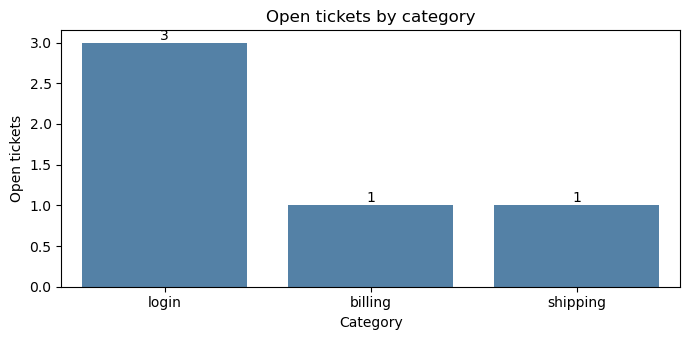

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 3.5))

ax = sns.countplot(
    data=open_tickets,
    x="category",
    color="steelblue",
)

# Add a count above each bar
ax.bar_label(ax.containers[0])

plt.title("Open tickets by category")
plt.xlabel("Category")
plt.ylabel("Open tickets")
plt.tight_layout()
plt.show()

**Check your understanding** — Does billing appear even though its wait time is missing?  
**Answer** — Yes. The chart counts open rows by category, so it shows login 3, billing 1, and shipping 1. Use the pandas count to confirm the bars.

### Chart 2 · How are the known waits spread out?

A histogram puts numbers into ranges called bins. A taller bar means more observations landed in that range. The dashed line marks the 30-minute threshold used by our Python tool.

- `known_waits` comes from the open tickets after dropping missing waits.
- `bins=[20, 30, 40, 50, 60, 70]` places the bin edges at these minutes.
- `plt.axvline(30, ...)` draws the threshold line.

**Before you run the cell** — How can we show the distribution of known open-ticket wait times and mark the 30-minute threshold?

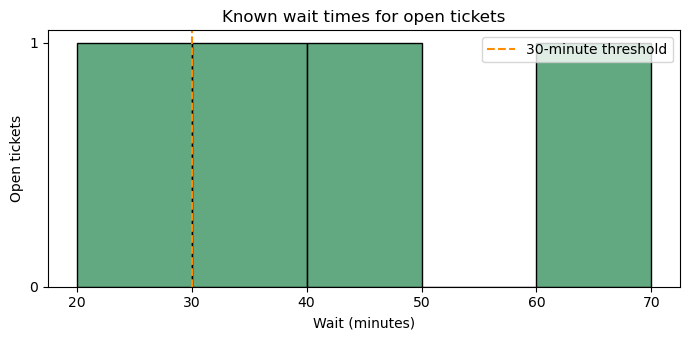

In [19]:
plt.figure(figsize=(7, 3.5))
sns.histplot(x=known_waits, bins=[20, 30, 40, 50, 60, 70], color="seagreen")
plt.axvline(30, color="darkorange", linestyle="--", label="30-minute threshold")
plt.title("Known wait times for open tickets")
plt.xlabel("Wait (minutes)")
plt.ylabel("Open tickets")
plt.yticks([0, 1])
plt.legend()
plt.tight_layout()
plt.show()

**Check your understanding** — Why does this chart show four tickets when the first one shows five?  
**Answer** — One open ticket has an unknown wait. The four known waits are 22, 30, 40, and 65 minutes. Three are at or above 30. This small dataset lets us check every bar by hand.

**Try it** — Move the dashed line to 45 minutes. Check the new count with pandas using `(known_waits >= 45).sum()`. Expect one ticket. Moving the line only changes the display. Pass 45 to the calculation to change the rule.

**Agent connection** — A support workflow can use the calculated count to flag a backlog and show the chart to a human. It can pass the count and threshold to the LLM for a short update.

[Seaborn count plots](https://seaborn.pydata.org/generated/seaborn.countplot.html) · [Seaborn histograms](https://seaborn.pydata.org/generated/seaborn.histplot.html)

**Common question · Is the empty interval in the histogram a missing value?**  
**Answer** — It means zero known waits fell from 50 up to 60 minutes. The ticket with the missing wait was removed before we drew the histogram, so it has no position on the chart.

**Common question · Can I use the histogram to count how many are at least 45 minutes?**  
**Answer** — Use the exact waits to get that count. Forty-five falls inside the 40-to-50 bin. The bar for that bin can't tell us which side of 45 the ticket is on.

Suppose the lead asks the same question again tomorrow. We can put the calculation in one function and reuse it on the new table.

### Optional · More charts for the support lead

We have counted the categories and looked at the wait-time ranges. Different questions call for different charts. Let's look at a box plot, a scatter plot, and a line plot. Each example creates a small dataset so you can teach it on its own.

These examples use `pd`, `plt`, and `sns` imported earlier. The sample records below are made up for teaching. Run the charts you want to explore.

#### Box plot · How are waits spread out?

The manager wants to understand the middle of the wait times and whether any recorded waits stand out. A box plot summarizes a group of numbers. Let's look at the chart and then compare it with the values.

- The line inside the box shows the median, the middle value.
- The bottom and top of the box show the 25th and 75th percentiles. The box contains the middle half of the data.
- The whiskers extend to the most extreme values within the standard 1.5-times-interquartile-range rule.
- A point beyond a whisker is shown separately as a potential outlier. It is a value to investigate.

**Before you run the cell** — Which value do you think will stand out, and what is the middle wait?

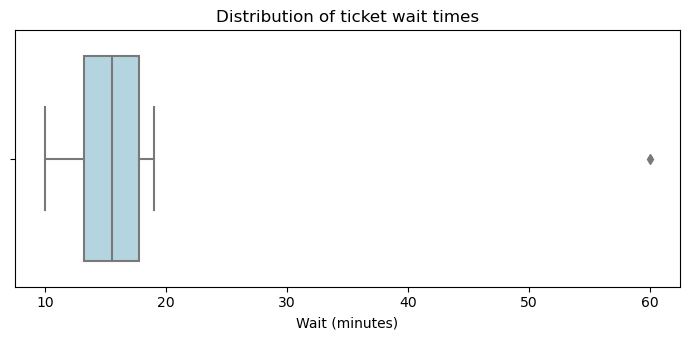

Median wait: 15.5


In [20]:
box_waits = pd.DataFrame({
    "wait_minutes": [10, 12, 13, 14, 15, 16, 17, 18, 19, 60]
})

plt.figure(figsize=(7, 3.5))
sns.boxplot(data=box_waits, x="wait_minutes", color="lightblue")
plt.title("Distribution of ticket wait times")
plt.xlabel("Wait (minutes)")
plt.tight_layout()
plt.show()

print("Median wait:", box_waits["wait_minutes"].median())

**Expected** — The median is 15.5 minutes. The plot shows 60 minutes as a separate point beyond the upper whisker.

**Check your understanding** — Does a separate point tell us the 60-minute wait is an error?  
**Answer** — It tells us the value stands out according to the box plot's rule. It could be a real wait or a data error. We need more information.

#### Scatter plot · Do longer messages take longer to resolve?

Now each dot is one ticket. Its position left to right shows the message length. Its position up and down shows the resolution time. We can look for a pattern and discuss tickets that do not follow it.

**Before you run the cell** — Which ticket took the longest to resolve? Does a longer message always mean a longer resolution time?

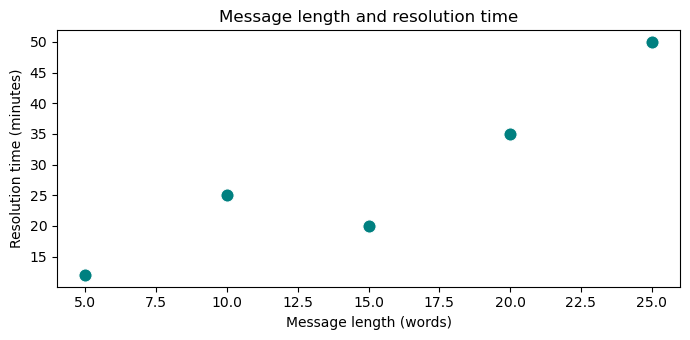

In [21]:
ticket_details = pd.DataFrame({
    "ticket_id": [201, 202, 203, 204, 205],
    "message_words": [5, 10, 15, 20, 25],
    "resolution_minutes": [12, 25, 20, 35, 50],
})

plt.figure(figsize=(7, 3.5))
sns.scatterplot(
    data=ticket_details,
    x="message_words",
    y="resolution_minutes",
    s=90,
    color="teal",
)
plt.title("Message length and resolution time")
plt.xlabel("Message length (words)")
plt.ylabel("Resolution time (minutes)")
plt.tight_layout()
plt.show()

**Answer** — Ticket 205 took 50 minutes. In this tiny example, longer messages tend to have longer resolution times, but the pattern is not exact. Ticket 203 has more words than ticket 202 and a shorter resolution time.

**Check your understanding** — Does this show that long messages cause delays?  
**Answer** — We have only observed values in a small sample. Other factors, such as the complexity of the problem, might also affect the time.

#### Line plot · How does the backlog change over days?

A line plot helps us see how a number changes over time. Here we record the open-ticket backlog at the end of each day. One point is one day's count.

**Before you run the cell** — On which day did the queue reach its highest count?

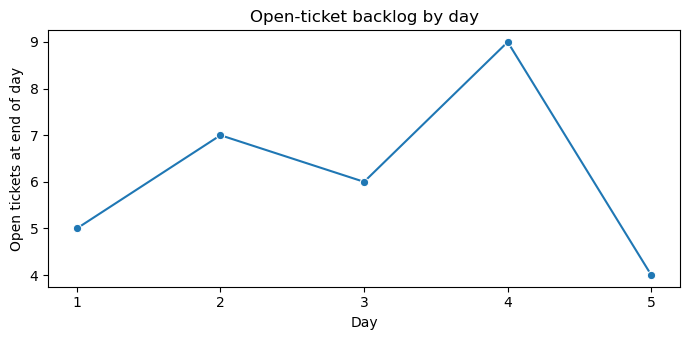

In [22]:
daily_backlog = pd.DataFrame({
    "day": [1, 2, 3, 4, 5],
    "open_count": [5, 7, 6, 9, 4],
})

plt.figure(figsize=(7, 3.5))
sns.lineplot(data=daily_backlog, x="day", y="open_count", marker="o")
plt.xticks(daily_backlog["day"])
plt.title("Open-ticket backlog by day")
plt.xlabel("Day")
plt.ylabel("Open tickets at end of day")
plt.tight_layout()
plt.show()

**Answer** — Day 4, with 9 open tickets. The count fell to 4 on day 5.

**Check your understanding** — What is the difference between this chart and the first count plot?  
**Answer** — The line plot shows how the recorded backlog changes over time. The count plot compares how many open tickets are in each category at one point in the sample.

**Agent connection** — An agent's reporting tool could calculate the daily backlog and pass the numbers to a model for an update. A person can use the chart to inspect the pattern.

## Package the calculation as a tool

So far we ran several cells to answer one question. A program that needs the same facts should be able to call one function. Give it the ticket table and a threshold in minutes. It sends back a dictionary of named results that we can inspect, test, or pass to a model.

- `data: pd.DataFrame` describes the input table. This example expects the columns in the sample CSV.
- `threshold_minutes: int = 30` makes 30 the default. A caller can supply a different limit.
- `-> dict[str, object]` describes a dictionary with string keys and values of different types.
- If there are no known open waits, the average is `None`. In JSON it becomes `null`.

**Read the function in order** — Select open rows, keep the known waits, calculate the metrics, and return them together.

**Before you run the cell** — How can we package these calculations into one reusable function that accepts a table and a threshold?

In [23]:
def ticket_facts(
    data: pd.DataFrame, threshold_minutes: int = 30
) -> dict[str, object]:
    open_rows = data[data["status"] == "open"]
    open_waits = open_rows["wait_minutes"]
    known_waits = open_waits.dropna()
    average = None

    if len(known_waits) > 0:
        average = round(float(known_waits.mean()), 2)

    return {
        "total_tickets": len(data),
        "open_tickets": len(open_rows),
        "unknown_open_waits": int(open_waits.isna().sum()),
        "threshold_minutes": threshold_minutes,
        "open_at_or_above_threshold": int((known_waits >= threshold_minutes).sum()),
        "average_known_open_wait_minutes": average,
    }


facts = ticket_facts(tickets)
print(facts)

{'total_tickets': 7, 'open_tickets': 5, 'unknown_open_waits': 1, 'threshold_minutes': 30, 'open_at_or_above_threshold': 3, 'average_known_open_wait_minutes': 39.25}


Expect 7 total, 5 open, 1 unknown open wait, 3 open tickets at or above 30 minutes, and a 39.25-minute average for the known open waits.

**Check your understanding** — What changes if we call `ticket_facts(tickets, 45)`?  
**Answer** — The threshold becomes 45 and the count at or above the threshold becomes 1. The average and the other counts stay the same.

**Agent connection** — An agent could call this tool with a threshold taken from the user's question. The model would receive the calculated values as evidence for its answer.

**Common question · Does the type hint enforce that the threshold is an integer?**  
**Answer** — It tells a reader and their editor what the function expects. To reject invalid input at runtime, we would add an explicit check, like the ticket ID check from Saturday.

## HTTP and `requests`

We got our ticket data from a file. An application could also get data from another program over the internet. An API tells us what to send and what to expect back. Let's start by asking a practice API for one task. Then we'll use the same request-and-response idea to ask a model for a sentence.

- `GET` asks for a resource. Our example reads the task with ID 1.
- `POST` sends data for a server to process. Our chat example sends a prompt and asks for a reply.

| Word | Meaning in this class |
| --- | --- |
| URL | The address of the endpoint |
| Headers | Extra request information, such as authorization |
| Body | The data we send with POST |
| Status code | The server's signal for success or failure |
| JSON | A text format both programs can read |

The next cell uses the [JSONPlaceholder practice API](https://jsonplaceholder.typicode.com/). If it cannot be reached, the cell labels its example response so you can still explore the same fields. `timeout` limits how long Requests waits for a connection or for incoming data.

In [24]:
try:
    response = requests.get(
        "https://jsonplaceholder.typicode.com/todos/1", timeout=10
    )
    response.raise_for_status()
    todo = response.json()
    print("HTTP status:", response.status_code)
except requests.RequestException:
    print("Practice API unavailable. Showing sample data.")
    todo = {"id": 1, "title": "Check the support queue", "completed": False}

print(todo["id"], todo["title"], todo["completed"])

HTTP status: 200
1 delectus aut autem False


- `.raise_for_status()` raises an exception for a 4xx or 5xx HTTP error.
- `.json()` parses the response body into Python values. In the practice example, the result is a dictionary.
- If the practice API is unavailable, use the labeled sample data to find the same three fields.

**Check your understanding · What does `completed=False` tell us if the HTTP status is 200?**  
**Answer** — The request succeeded. Inside the response, the task itself is still incomplete. Those fields answer different questions.

**Common question · Why use a timeout?**  
**Answer** — A service can be slow or unreachable. We set a time limit on how long the code waits for a connection or for incoming data, so we can handle a failure and continue.

Now we'll ask for a sentence we could send to the support lead. We already have the numbers. Our prompt will tell the model which facts to keep and how long the reply should be.

- The f-strings insert the open count, the number at or above the threshold, and the threshold.
- We give the model those facts in a user message. The full statistics dictionary goes in our saved report.
- When we call the chat endpoint, `requests.post(..., json=payload)` encodes the request body as JSON.

In [25]:
import json


def build_prompt(facts: dict[str, object]) -> str:
    open_count = facts["open_tickets"]
    long_wait_count = facts["open_at_or_above_threshold"]
    threshold = facts["threshold_minutes"]
    return (
        "You are writing a support desk update. Rewrite the two facts below in one sentence. "
        "Use only these facts and keep every number the same.\n"
        f"There are {open_count} open tickets.\n"
        f"{long_wait_count} of those open tickets have waited at least {threshold} minutes."
    )


prompt = build_prompt(facts)
print(prompt)

You are writing a support desk update. Rewrite the two facts below in one sentence. Use only these facts and keep every number the same.
There are 5 open tickets.
3 of those open tickets have waited at least 30 minutes.


**Check the model's answer** — The calculated count at the 30-minute threshold is three. Ticket IDs 101, 103, and 107 qualify. Compare any number the model gives you with the filtered table or the values in `facts`.

The prompt supplies the open-ticket count, the wait threshold, and the number of known waits that meet it. Those are the facts the model needs to write the update.

## Local Ollama and hosted Groq

### Local LLM with Ollama

You can send the same prompt to two different services. Ollama runs Qwen3.5 4B on your computer. Groq runs a hosted model and receives requests over the internet.

**Setup**

- Open Ollama and run `ollama list` in a terminal. If `qwen3.5:4b` is missing, run `ollama pull qwen3.5:4b`.
- If the Ollama app is unavailable and the CLI is installed, run `ollama serve` in another terminal.
- Run this call with a local notebook kernel. In hosted Colab, `127.0.0.1` points to the Colab runtime.

**Walk through the request**

- `model` selects Qwen3.5 4B by default.
- `messages` contains our user message. The `role` says who sent it, and `content` holds the prompt.
- `stream: False` gives us one JSON response after generation. `think: False` requests a direct answer.
- The settings ask for low variation in the example using a temperature of zero.

Run the next cell to define the function. Uncomment its final line when you're ready for the live call.

In [26]:
def ask_ollama(prompt: str, model: str = "qwen3.5:4b") -> str:
    payload = {
        "model": model,
        "messages": [{"role": "user", "content": prompt}],
        "stream": False,
        "think": False,
        "options": {"temperature": 0},
    }

    response = requests.post(
        "http://127.0.0.1:11434/api/chat", json=payload, timeout=90
    )
    response.raise_for_status()
    return response.json()["message"]["content"]


# print(ask_ollama(prompt))

The function reads `["message"]["content"]`. The first key gives the reply message. The second gives the answer text. The first call can take longer while the model loads. If the connection fails, check whether Ollama is running. If the model is missing, check the name with `ollama list`. You can use the offline report if Ollama is unavailable.

**Sample from Qwen3.5 4B** — “Of the five open tickets, three have been waiting for at least thirty minutes.” Compare any new answer with the facts. If you try a different threshold, check the new counts again.

[Ollama chat API](https://docs.ollama.com/api/chat) · [Qwen model](https://ollama.com/library/qwen3.5:4b)

**Common question · Why can the first request take longer?**  
**Answer** — Ollama may need to load the model into memory first. Subsequent requests can use the loaded model.

**Common question · Does this call send my prompt to a company server?**  
**Answer** — This call goes to the local Ollama service at `127.0.0.1`, where we are using an installed model. The Groq call in the next section sends the prompt to a remote service.

### Hosted LLM with Groq

Groq runs the model on a remote server. Our Python code sends the prompt over the internet. The API key is a credential we send in a header. The prompt goes in the body.

Run the notebook from the course folder or one of its subfolders. The setup searches up from the kernel’s working folder for `.env` and loads `GROQ_API_KEY` into the kernel’s environment. The same function also works if the key is already set in the environment.

- For local setup, add `GROQ_API_KEY` to the project’s Git-ignored `.env` file. [Groq API Keys](https://console.groq.com/keys)
- On hosted Colab, add `GROQ_API_KEY` to Colab Secrets and enable notebook access. Uncomment the two Colab lines below.
- To enter the key for this session, uncomment the **Hidden-input option**.
- Uncomment the final line when you are ready to make the live call.

The header carries the API key so Groq can check whether we can make the request. The body carries the model name and what we want it to say. We'll look at the response text without displaying the key.

In [27]:
import os
from getpass import getpass

from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))


def ask_groq(prompt: str) -> str:
    api_key = os.getenv("GROQ_API_KEY")
    if not api_key:
        raise RuntimeError("A Groq API key is needed.")

    headers = {"Authorization": f"Bearer {api_key}"}
    payload = {
        "model": "openai/gpt-oss-20b",
        "messages": [{"role": "user", "content": prompt}],
        "reasoning_effort": "low",
        "max_completion_tokens": 512,
    }

    response = requests.post(
        "https://api.groq.com/openai/v1/chat/completions",
        headers=headers,
        json=payload,
        timeout=30,
    )
    response.raise_for_status()
    return response.json()["choices"][0]["message"]["content"]


# Hidden-input option
# os.environ["GROQ_API_KEY"] = getpass("Groq API key: ").strip()

# Colab Secrets option
# from google.colab import userdata
# os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
# print(ask_groq(prompt))

The response starts with a list called `choices`. Pick its first entry with `[0]`, then read its message content. `reasoning_effort` and `max_completion_tokens` keep the example short. Compare both answers against the facts. A good answer says five tickets are open and three known waits meet the 30-minute threshold. Wording can vary.

**Check your understanding** — Which line is different because Groq is hosted?  
**Answer** — The URL points to Groq's server, and we send an authorization header. Both calls send a message and read the reply text.

**If the call fails** — 401 usually points to credentials. 429 means a request limit was reached. The offline report below runs without a model service.

[Groq chat API](https://console.groq.com/docs/api-reference#chat-create) · [Groq supported models](https://console.groq.com/docs/models)

**Common question · Why does the Python code read a different field for each provider?**  
**Answer** — Both APIs return a reply in JSON. Ollama puts the reply under `message`. Groq puts it under the first item in `choices`. Our two functions return the same kind of value, a string, so the reporting code can use either one.

**Check your understanding · If both replies use different words, can both be correct?**  
**Answer** — Yes. Check for five open tickets, three waits meeting the threshold, and the threshold of 30 minutes. Wording can vary while those facts stay the same.

## Put the data and LLM call together

Imagine the support lead needs this update every morning. The program opens the latest CSV, calculates the facts, and asks a model for a sentence. We save both the numbers and the sentence so a person can compare them later.

- Start with `provider="offline"` to show the full file flow. Python supplies a short summary in that mode.
- After a live call works, choose `"ollama"` or `"groq"` to include a model reply in the report.
- Watch `summary_source`. It records which path supplied the summary.

In [28]:
def build_ticket_report(
    path: Path, provider: str = "offline"
) -> dict[str, object]:
    data = pd.read_csv(path)
    facts = ticket_facts(data)
    prompt = build_prompt(facts)
    source = provider

    try:
        if provider == "ollama":
            summary = ask_ollama(prompt)
        elif provider == "groq":
            summary = ask_groq(prompt)
        elif provider == "offline":
            summary = f"There are {facts['open_tickets']} open tickets."
        else:
            raise ValueError("Choose offline, ollama or groq.")

        if not isinstance(summary, str) or not summary.strip():
            raise RuntimeError("The model returned an empty answer.")
    except (requests.RequestException, RuntimeError, KeyError, IndexError, TypeError):
        summary = "The model reply was unavailable. Use the computed facts."
        source = "fallback"

    return {"facts": facts, "summary": summary, "summary_source": source}

**When the model request fails**

Suppose the model service times out. We already calculated the ticket numbers, so we can still save them. The report explains that the model reply was unavailable and sets `summary_source` to `"fallback"`.

**Common question · What if it is the CSV that is missing?**  
**Answer** — The program reads the CSV before it tries to call the model. If the file is missing, pandas raises an error at that step. We need the data before we can calculate a report.

In [29]:
report = build_ticket_report(csv_path, provider="offline")
report_path = Path("sunday_ticket_report.json")

with report_path.open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print(report_path.read_text(encoding="utf-8"))

{
  "facts": {
    "total_tickets": 7,
    "open_tickets": 5,
    "unknown_open_waits": 1,
    "threshold_minutes": 30,
    "open_at_or_above_threshold": 3,
    "average_known_open_wait_minutes": 39.25
  },
  "summary": "There are 5 open tickets.",
  "summary_source": "offline"
}


**Expected** — The report contains the calculated facts, the sentence `There are 5 open tickets.`, and `"summary_source": "offline"`. Rerunning the cell writes `sunday_ticket_report.json` again in the current working folder.

**Check your understanding · Would you call this whole notebook an agent?**  
**Answer** — We built a workflow where we write down the steps in advance. In a later agent lesson, the model can choose which tool to request based on the user's question. The application runs the tool, and the model can use the result in its answer.

### Optional · Two scenarios to try live

**Scenario A · A different threshold**

The lead wants to see only tickets that have waited at least 45 minutes. Predict which tickets still qualify before running the cell. Does the average known wait change?

**Answer** — Ticket 103 is the only match. There are still five open tickets and the average is still 39.25 minutes. The threshold changes which waits are counted. The next cell shows the new facts and the prompt the model would receive.

In [30]:
facts_at_45 = ticket_facts(tickets, threshold_minutes=45)
print(facts_at_45)
print(build_prompt(facts_at_45))

{'total_tickets': 7, 'open_tickets': 5, 'unknown_open_waits': 1, 'threshold_minutes': 45, 'open_at_or_above_threshold': 1, 'average_known_open_wait_minutes': 39.25}
You are writing a support desk update. Rewrite the two facts below in one sentence. Use only these facts and keep every number the same.
There are 5 open tickets.
1 of those open tickets have waited at least 45 minutes.


**Scenario B · A ticket was closed**

Ticket 107 is resolved. It was open for 30 minutes. Predict the open count, the count at or above 30 minutes, and what happens to the average.

**Answer** — Four tickets are now open. Two known waits meet the threshold. The average rises to 42.33 minutes because the 30-minute wait dropped out of the average. The example uses a copy of the DataFrame so you can return to the original data afterward.

In [31]:
updated_tickets = tickets.copy()
updated_tickets.loc[updated_tickets["ticket_id"] == 107, "status"] = "closed"
updated_facts = ticket_facts(updated_tickets)
print(updated_facts)

{'total_tickets': 7, 'open_tickets': 4, 'unknown_open_waits': 1, 'threshold_minutes': 30, 'open_at_or_above_threshold': 2, 'average_known_open_wait_minutes': 42.33}


## Check your understanding

1. Which function calculates the ticket counts?
2. Why does the category chart include five tickets when the histogram includes four waits?
3. What can the report still contain if the model call fails?
4. Which value would you change to count open tickets with waits of at least 45 minutes?

**Check your answers** — `ticket_facts()` calculates the counts. One open ticket has an unknown wait. If a model call fails, the report can still contain the calculated facts and a fallback message. Pass `threshold_minutes=45` to change the rule.